# TP3. Reconstrucción 3D y estimación de pose

Visión por Computadora - Robótica Móvil

**Cómo usarlo:** Dejar este notebook en la raíz del repo (`TP3/`), completar la celda de configuración y ejecutar todo con *Run All*. En caso de que haya salidas mostradas, hacer un Restart Kernel para borrar cualquier estado viejo.

Las figuras obtenidas se guardan en `figures/`.

Todas las imágenes del dataset van en `./data/stereo_example/cam0` para las imágenes de la cámara izquierda y `./data/stereo_example/cam1` para la cámara derecha.

El ground truth `data.csv` se guarda en el directorio `./data/`

> El nombre de las imagenes stereo originales es el mismo, tanto para cámara izquierda como derecha. Se identidican de acuerda a la carpeta donde están.
> Esto es así porque en los dataset las imagenes se guardan con el nombre de acuerdo al timestamp de cuando fueron capturadas.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np
import yaml
import pandas as pd
import os
import csv

ROOT = Path.cwd() # La notebook va en la raíz del repo (TP3)
CALIB_DIR = ROOT / "results/calibration" # left.yaml y right.yaml obtenidos con la calibración del Ej 1
SEQ_DIR = ROOT / "data/stereo_example" # Carpeta que contiene los directorios cam0 y cam1
FRAME = "1403636579763555584.png" # Nombre de las imagenes ()
FRAME2 = "1403636581013555456.png"
FIG_DIR = ROOT / "figures" # Acá se guardan las figuras obtenidas a lo largo de los ejercicio
GT_PATH = ROOT / "data/data.csv" # Ground-truth

FIG_DIR.mkdir(exist_ok=True)
LEFT_PATH = SEQ_DIR / "cam0" / FRAME
RIGHT_PATH = SEQ_DIR / "cam1" / FRAME
LEFT_PATH2 = SEQ_DIR / "cam0" / FRAME2
RIGHT_PATH2 = SEQ_DIR / "cam1" / FRAME2

ground_truth = []

with open(GT_PATH, 'r') as f:
    reader = csv.reader(f)
    header = next(reader)
    for row in reader:
        tmstmp = int(row[0])
        x, y, z = float(row[1]), float(row[2]), float(row[3])
        qw, qx, qy, qz = float(row[4]), float(row[5]), float(row[6]), float(row[7])
        ground_truth.append([tmstmp, x, y, z, qw, qx, qy, qz])

list_izq = os.listdir(SEQ_DIR/"cam0")
list_izq = sorted(list_izq)
list_der = os.listdir(SEQ_DIR/"cam1")
list_der = sorted(list_der)

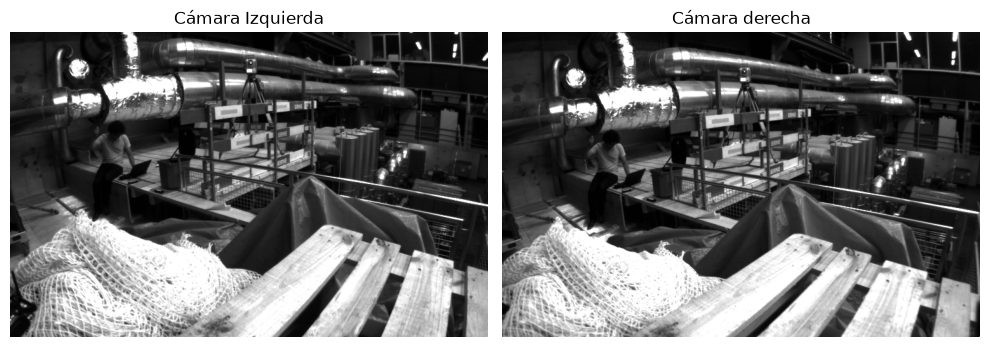

In [2]:
img1 = cv2.imread(LEFT_PATH)
img2 = cv2.imread(RIGHT_PATH)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(img1, cmap='gray')
axes[0].axis('off')
axes[0].set_title("Cámara Izquierda")

axes[1].imshow(img2, cmap='gray')
axes[1].axis('off')
axes[1].set_title("Cámara derecha")

plt.tight_layout()
plt.show()

In [3]:
def show(img, title="", size=(12, 5)):
    plt.figure(figsize=size)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB) if img.ndim == 3 else img, cmap="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()


def save(img, name):
    cv2.imwrite(str(FIG_DIR / name), img)

# Ej. 1. Calibración de la cámara estéreo

Calibración hecha con `ros2 run camera_calibration cameracalibrator` sobre `cam_checkerboard` (tablero 7×6). Los yaml que guarda el calibrador traen `K` (intrínseca), `D` (distorsión), y la rectificación (`R`, `P`) de cada cámara. La pose entre cámaras y el error de reproyección solo salieron por terminal; están copiados más abajo.

## Salida en la terminal luego de la calibración

```shell
Stereo RMS re-projection error: 0.2659409146589982

Left:
D = [-0.28454587860679176, 0.07562820138166555, 0.0003791677575551562, 0.00012090717268091055, 0.0]
K = [461.67318458071037, 0.0, 368.0679817907219, 0.0, 460.4108640633701, 247.63174634147535, 0.0, 0.0, 1.0]
R = [0.9999855127648051, -0.0012956153536859353, 0.005224523075363776, 0.001260931031323702, 0.9999771825905618, 0.006636591834408091, -0.005233002335558448, -0.006629907925271702, 0.9999643293675321]
P = [439.2536534174921, 0.0, 371.33053970336914, 0.0, 0.0, 439.2536534174921, 256.0329170227051, 0.0, 0.0, 0.0, 1.0, 0.0]

Right:
D = [-0.2866006602364961, 0.07774236863472772, -0.0003191969270104431, 0.0003244000114631708, 0.0]
K = [460.97751449612394, 0.0, 375.6607261513001, 0.0, 460.0253197978464, 254.888853512581, 0.0, 0.0, 1.0]
R = [0.9999727666707475, -0.0036153003111019976, -0.006433935072045855, 0.003572542427770412, 0.9999715413022566, -0.006644811975601251, 0.006457774961434948, 0.006621645509226493, 0.9999572245617796]
P = [439.2536534174921, 0.0, 371.33053970336914, -48.132983792612535, 0.0, 439.2536534174921, 256.0329170227051, 0.0, 0.0, 0.0, 1.0, 0.0]
self.T = [-0.10957603333914648, 0.0003961610562057416, 0.0007050242841150852]
self.R = [0.9999289910082404, 0.0022340663884456383, 0.01170563490863621, -0.002389003874944096, 0.9999095076807233, 0.013238924056699056, -0.011674999003330461, -0.013265948781205223, 0.999843842307991]
None
# oST version 5.0 parameters


[image]

width
752

height
480

[narrow_stereo/left]

camera matrix
461.673185 0.000000 368.067982
0.000000 460.410864 247.631746
0.000000 0.000000 1.000000

distortion
-0.284546 0.075628 0.000379 0.000121 0.000000

rectification
0.999986 -0.001296 0.005225
0.001261 0.999977 0.006637
-0.005233 -0.006630 0.999964

projection
439.253653 0.000000 371.330540 0.000000
0.000000 439.253653 256.032917 0.000000
0.000000 0.000000 1.000000 0.000000
# oST version 5.0 parameters


[image]

width
752

height
480

[narrow_stereo/right]

camera matrix
460.977514 0.000000 375.660726
0.000000 460.025320 254.888854
0.000000 0.000000 1.000000

distortion
-0.286601 0.077742 -0.000319 0.000324 0.000000

rectification
0.999973 -0.003615 -0.006434
0.003573 0.999972 -0.006645
0.006458 0.006622 0.999957

projection
439.253653 0.000000 371.330540 -48.132984
0.000000 439.253653 256.032917 0.000000
0.000000 0.000000 1.000000 0.000000

('Wrote calibration data to', '/tmp/calibrationdata.tar.gz')
('Wrote calibration data to', '/tmp/calibrationdata.tar.gz')
```

In [4]:
def load_camera_info(path):
    with open(path) as f:
        d = yaml.safe_load(f)
    K = np.array(d["camera_matrix"]["data"], dtype=np.float64).reshape(3, 3)
    D = np.array(d["distortion_coefficients"]["data"], dtype=np.float64).reshape(5, 1)
    R = np.array(d["rectification_matrix"]["data"], dtype=np.float64).reshape(3, 3)
    P = np.array(d["projection_matrix"]["data"], dtype=np.float64).reshape(3, 4)
    size = (d["image_width"], d["image_height"])
    return K, D, R, P, size


Kl, Dl, Rl, Pl, size = load_camera_info(CALIB_DIR / "left.yaml")
Kr, Dr, Rr, Pr, _ = load_camera_info(CALIB_DIR / "right.yaml")


T_stereo = np.array([-0.10957603333914648, 0.0003961610562057416, 0.0007050242841150852])

R_stereo = np.array([[0.9999289910082404, 0.0022340663884456383, 0.01170563490863621],
                     [-0.002389003874944096, 0.9999095076807233, 0.013238924056699056],
                     [-0.011674999003330461, -0.013265948781205223, 0.999843842307991]])

# Extrinsecos de las cámaras sobre el IMU
R_left = np.matrix([[0.0148655429818, -0.999880929698, 0.00414029679422],
                    [0.999557249008, 0.0149672133247, 0.025715529948],
                    [-0.0257744366974, 0.00375618835797, 0.999660727178]])
T_left = np.array([-0.0216401454975, -0.064676986768, 0.00981073058949])
P_right = np.matrix([[0.0125552670891, -0.999755099723, 0.0182237714554],
                    [0.999598781151, 0.0130119051815, 0.0251588363115],
                    [-0.0253898008918, 0.0179005838253, 0.999517347078]])
T_right = np.array([-0.0198435579556, 0.0453689425024, 0.00786212447038])
RMS = 0.2659409146589982

#print(Dl)
#print(Dr)

# Ej. 2a. Rectificar imágenes

Se usan directamente `R` y `P` de los yaml en `initUndistortRectifyMap`: desdistorsionan, rotan y reproyectan con la `K'` común en un solo `remap`.

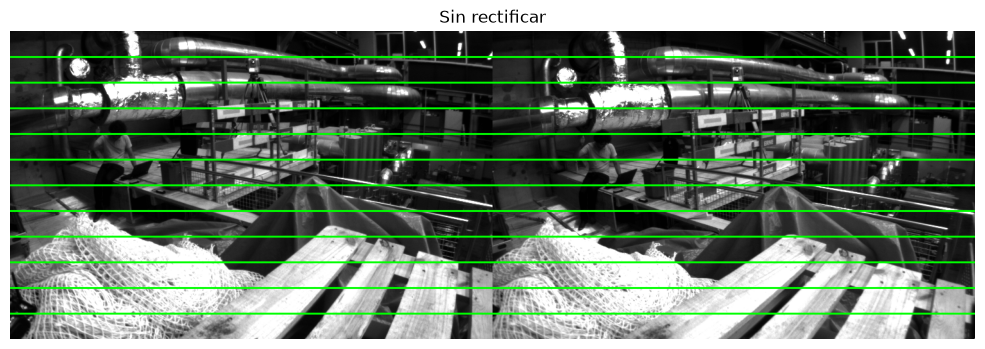

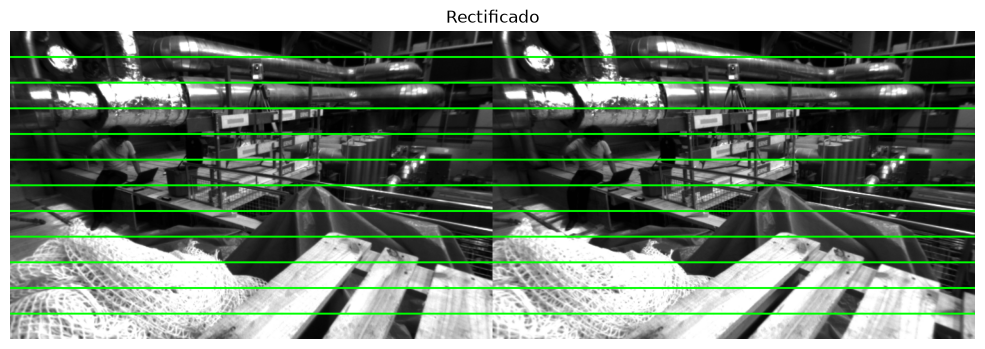

In [5]:
# Cargamos las imgs de prueba
left_raw = cv2.imread(str(LEFT_PATH), cv2.IMREAD_GRAYSCALE)
right_raw = cv2.imread(str(RIGHT_PATH), cv2.IMREAD_GRAYSCALE)


def rectify(img, K, D, R, P, size):
    # Calculamos donde mandar los pixeles para que la imagen se rectifique
    map1, map2 = cv2.initUndistortRectifyMap(K, D, R, P[:, :3], size, cv2.CV_32FC1)
    # Aplicamos la rectificación
    return cv2.remap(img, map1, map2, cv2.INTER_LINEAR)


def with_lines(left, right, step=40):
    out = cv2.cvtColor(np.hstack([left, right]), cv2.COLOR_GRAY2BGR)
    for v in range(step, out.shape[0], step):
        cv2.line(out, (0, v), (out.shape[1] - 1, v), (0, 255, 0), 2)
    return out

left_rect = rectify(left_raw, Kl, Dl, Rl, Pl, size)
right_rect = rectify(right_raw, Kr, Dr, Rr, Pr, size)

cmp_raw = with_lines(left_raw, right_raw)
cmp_rect = with_lines(left_rect, right_rect)
show(cmp_raw, "Sin rectificar", (14, 4))
show(cmp_rect, "Rectificado", (14, 4))
save(cmp_raw, "2a_raw.png")
save(cmp_rect, "2a_rect.png")

## Ej. 2b. Keypoints y descriptores

ORB (Oriented FAST and Rotated BRIEF) sobre las imágenes rectificadas.

Keypoints: izquierda=4959, derecha=4971
Info descriptores: (4959, 32), uint8 (256 bits)


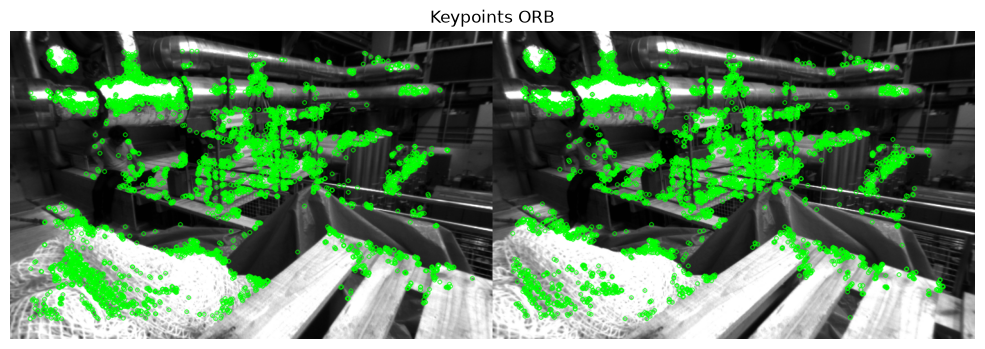

In [6]:
# Configuramos ORB
orb = cv2.ORB_create(nfeatures=5000)

# Obtenemos de una pasada la ubiicacion de los keypoints (kp_l | kp_r)
# y los descriptores (desc_l | desc_r)
kp_l, desc_l = orb.detectAndCompute(left_rect, None)
kp_r, desc_r = orb.detectAndCompute(right_rect, None)

print(f"Keypoints: izquierda={len(kp_l)}, derecha={len(kp_r)}")
print(f"Info descriptores: {desc_l.shape}, {desc_l.dtype} ({desc_l.shape[1] * 8} bits)")


# Obtenemos una matriz que representa el dibujo de los keypoints
vis_simple_l = cv2.drawKeypoints(
    image=left_rect, 
    keypoints=kp_l, 
    outImage=None, 
    color=(0, 255, 0)
)

vis_simple_r = cv2.drawKeypoints(
    image=right_rect, 
    keypoints=kp_r, 
    outImage=None, 
    color=(0, 255, 0)
)

# Ponemos una imagen (matriz) al lado de la otra
vis_kp = np.hstack([vis_simple_l, vis_simple_r])

show(vis_kp, "Keypoints ORB", (14, 4))
save(vis_kp, "2b_keypoints.png")

## Ej.2c. Matching

`BFMatcher` con distancia de Hamming. Se muestran todos los matches y los de distancia < 30.

Todos los matches: 4959 | con distancia menor a 30: 1763


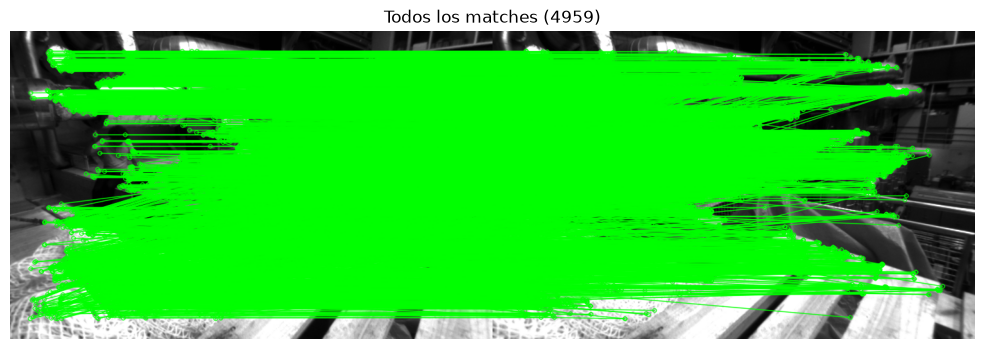

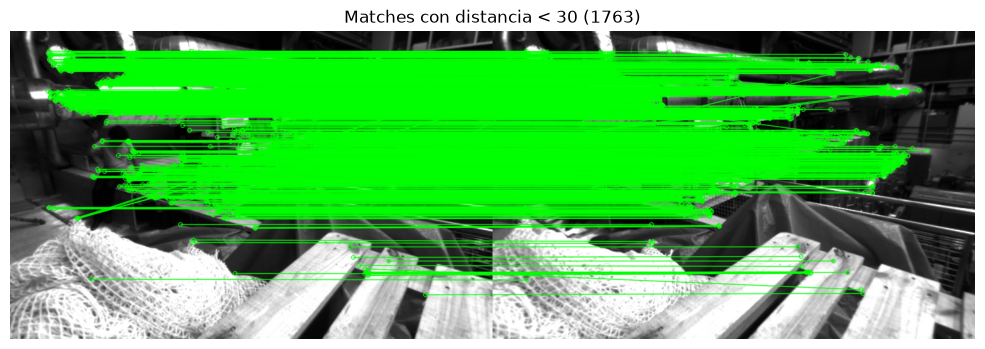

In [7]:
MAX_DIST = 30

matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
matches = matcher.match(desc_l, desc_r)

good = [m for m in matches if m.distance < MAX_DIST]
print(f"Todos los matches: {len(matches)} | con distancia menor a {MAX_DIST}: {len(good)}")

flags = cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS
vis_all = cv2.drawMatches(left_rect, kp_l, right_rect, kp_r, matches, None, matchColor=(0, 255, 0), flags=flags)
vis_good = cv2.drawMatches(left_rect, kp_l, right_rect, kp_r, good, None, matchColor=(0, 255, 0), flags=flags)
show(vis_all, f"Todos los matches ({len(matches)})", (14, 4))
show(vis_good, f"Matches con distancia < {MAX_DIST} ({len(good)})", (14, 4))
save(vis_all, "2cmatches_all.png")
save(vis_good, f"2cmatches_dist{MAX_DIST}.png")

## Ej. 2d. Triangulación de puntos 3D

**Nota sobre la función.** El enunciado pide `cv::sfm::triangulatePoints`, que pertenece al módulo `sfm` de opencv_contrib. Ese módulo parece no estár en los paquetes de pip (y no pude instalarlo, ja), así que se usó `cv2.triangulatePoints`

**Visualización.** El enunciado sugiere publicar un `PointCloud2` en RViz. Acá se muestra la nube con matplotlib, con el color del píxel de la imagen izquierda en cada punto. Además se dibuja cada punto sobre la imagen coloreado por profundidad.

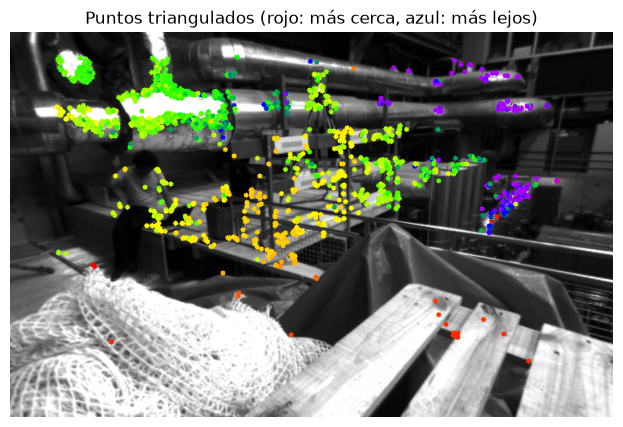

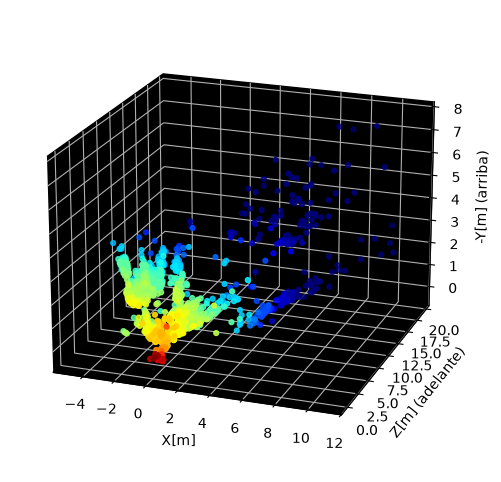

In [8]:
# Píxeles de los matches buenos (2c), en formato 2xN que nos pide cv2.triangulatePoints
pts_l = np.array([kp_l[m.queryIdx].pt for m in good], dtype=np.float64).T
pts_r = np.array([kp_r[m.trainIdx].pt for m in good], dtype=np.float64).T

# Le pasamos a la función trianguladora las matrices de proyección y los puntos obtenidos anteiormente
X_h = cv2.triangulatePoints(Pl, Pr, pts_l, pts_r)
# Como X_h es homogenea, lo pasamos a coordenada normal (cartesianas)
X = (X_h[:3] / X_h[3]).T

# Mostramos solo puntos delante de la cámara y a menos de 20 m (para que un punto muy lejano no nos aplaste el eje)
ok = (X[:, 2] > 0) & (X[:, 2] < 20)
X, pts_ok = X[ok], pts_l[:, ok] # El enunciado pide cámara izquierda

# Figura 1- puntos sobre la imagen izquierda
vis_3d = cv2.cvtColor(left_rect, cv2.COLOR_GRAY2BGR)


z_norm = np.clip(X[:, 2] / 10 * 255, 0, 255).astype(np.uint8)
colors_z = cv2.applyColorMap(z_norm, cv2.COLORMAP_RAINBOW).squeeze()

for (u, v), color in zip(pts_ok.T, colors_z):
    cv2.circle(vis_3d, (int(u), int(v)), 3, color.tolist(), -1)

show(vis_3d, "Puntos triangulados (rojo: más cerca, azul: más lejos)")
save(vis_3d, "2d_depth.png")


# Figura 2- Nube de puntos 3D
u, v = np.round(pts_ok).astype(int)

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")

colors_z = cv2.applyColorMap(z_norm, cv2.COLORMAP_JET).squeeze() / 255
ax.scatter(X[:, 0], X[:, 2], -X[:, 1], c=colors_z, s=12)

for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_pane_color((0, 0, 0, 1))
ax.set_xlabel("X[m]"); ax.set_ylabel("Z[m] (adelante)"); ax.set_zlabel("-Y[m] (arriba)")
ax.view_init(elev=20, azim=-70)

fig.savefig(FIG_DIR / "2d_pointcloud.png", dpi=150)
plt.show()


## Ej. 2e. Filtrado de correspondencias espúreas (RANSAC y matriz fundamental)

Los matches tienen outliers: pares de keypoints que no son el mismo punto 3D.
RANSAC loopea sobre lo siguiente:
1. sortear el mínimo de matches necesario para ajustar un modelo
2. calcular el modelo con esa muestra
3. contar cuántos matches lo cumplen (inliers).

Se queda con el modelo con más inliers

Matches: 3144 | Inliers: 2212 | Outliers: 932


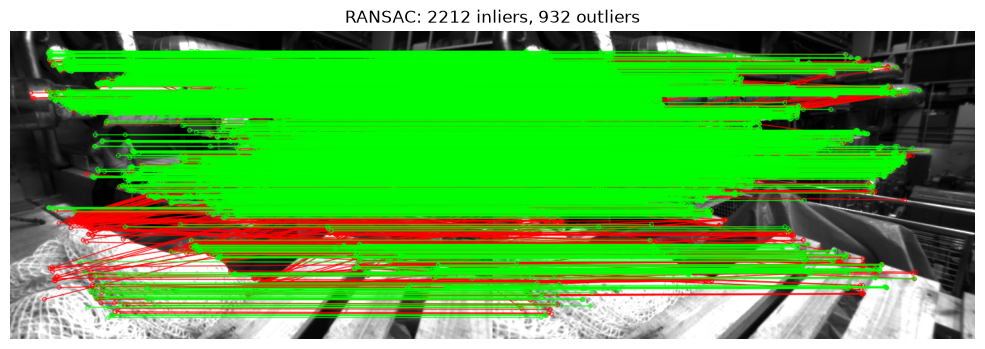

C:\Users\erigi\AppData\Local\Temp\ipykernel_19204\1902588141.py:47: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  ax.scatter(P[ok, 0], P[ok, 2], c=colors[ok], cmap="gray", vmin=0, vmax=1, s=8)


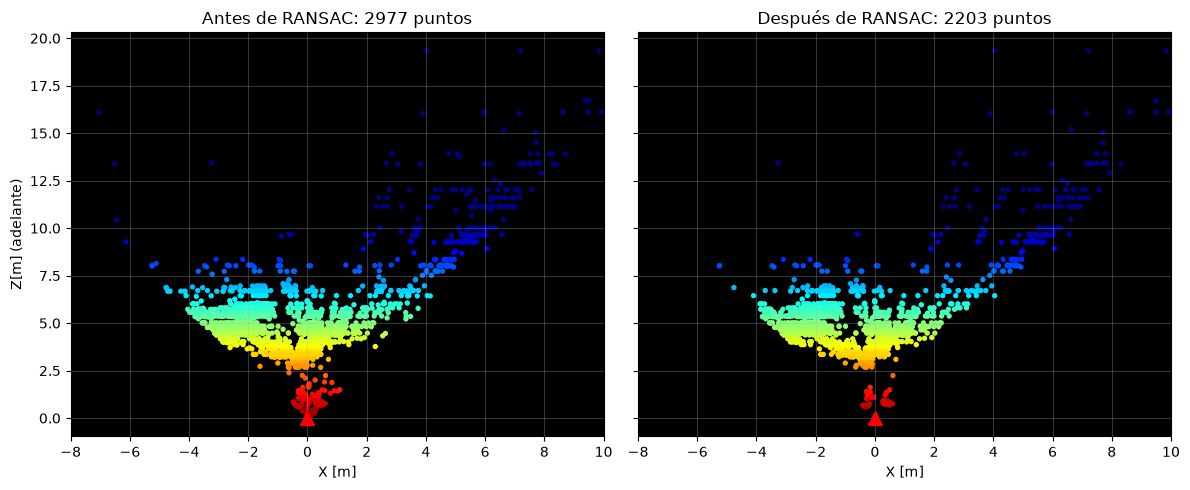

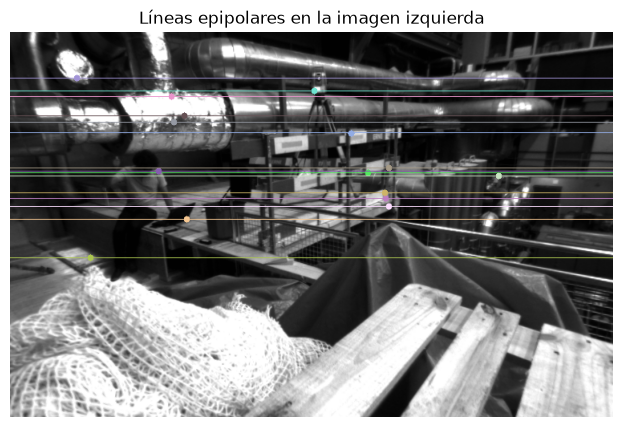

In [9]:

MAX_DIST_E = 50 # Cambiamos el filtro para esta prueba
cand = [m for m in matches if m.distance < MAX_DIST_E]

pts_l = np.float32([kp_l[m.queryIdx].pt for m in cand])
pts_r = np.float32([kp_r[m.trainIdx].pt for m in cand])

# Matriz fundamental y máscara de matches inliers y outliers
F, mask = cv2.findFundamentalMat(
    pts_l, pts_r, cv2.FM_RANSAC, 1.0, 0.999
)
inl = mask.ravel().astype(bool)

print(f"Matches: {len(cand)} | Inliers: {inl.sum()} | Outliers: {(~inl).sum()}")

# Mostramos matches. Verdes = inliers, rojos = outliers
flags = cv2.DRAW_MATCHES_FLAGS_NOT_DRAW_SINGLE_POINTS

vis = cv2.drawMatches(
    left_rect, kp_l, right_rect, kp_r,
    [m for m, ok in zip(cand, inl) if not ok],
    None, matchColor=(0, 0, 255), flags=flags
)
vis = cv2.drawMatches(
    left_rect, kp_l, right_rect, kp_r,
    [m for m, ok in zip(cand, inl) if ok],
    vis, matchColor=(0, 255, 0),
    flags=flags | cv2.DRAW_MATCHES_FLAGS_DRAW_OVER_OUTIMG
)

show(vis, f"RANSAC: {inl.sum()} inliers, {(~inl).sum()} outliers", (14, 4))
save(vis, "2e_matches_ransac.png")


# Triangulación de puntos de nuevo
def triangular(pl, pr):
    X = cv2.triangulatePoints(Pl, Pr, pl.T.astype(np.float64), pr.T.astype(np.float64))
    return (X[:3] / X[3]).T # Trasponemos (ahora cada punto está representado por una fila)

def draw_pointcloud(ax, P, title):
    # Mostramos solo puntos delante de la cámara y a menos de 20 m (para que un punto muy lejano no me aplaste el eje)
    ok = (P[:, 2] > 0) & (P[:, 2] < 20)

    # Color de cada punto según la imagen original izquierda
    z_norm = np.clip(P[:, 2] / 10 * 255, 0, 255).astype(np.uint8)
    colors = cv2.applyColorMap(z_norm, cv2.COLORMAP_JET).squeeze() / 255

    ax.scatter(P[ok, 0], P[ok, 2], c=colors[ok], cmap="gray", vmin=0, vmax=1, s=8)
    ax.plot(0, 0, "r^", ms=10)
    ax.set_title(f"{title}: {ok.sum()} puntos")
    ax.set_xlabel("X [m]")
    ax.set_facecolor("black")
    ax.grid(alpha=0.3)

# Puntos filtrados
new_l = pts_l[inl]
new_r = pts_r[inl]

# Antes y después de RANSAC
P_before = triangular(pts_l, pts_r)
P_after = triangular(new_l, new_r)

fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

draw_pointcloud(axs[0], P_before, "Antes de RANSAC")
draw_pointcloud(axs[1], P_after, "Después de RANSAC")

axs[0].set_ylabel("Z[m] (adelante)")
axs[0].set_xlim(-8, 10)
fig.tight_layout()
fig.savefig(FIG_DIR / "2e_pointcloud.png", dpi=150)
plt.show()


# Obtenemos las líneas epipolares en la imagen derecha
lines = cv2.computeCorrespondEpilines(new_r.reshape(-1, 1, 2), 2, F).reshape(-1, 3)

# Elegimos 15 puntos a azar
rng = np.random.default_rng(0)
idx = rng.choice(len(lines), size=15, replace=False)

vis_ep = cv2.cvtColor(left_rect, cv2.COLOR_GRAY2BGR)
h, w = vis_ep.shape[:2]

for i in idx:
    a, b, c = lines[i]
    u, v = new_l[i]

    color = tuple(map(int, rng.integers(80, 256, 3)))

    # Para dibujar una recta, no podemos usar los coeficinetes que me devuelve computeCorrespondEpilines
    y0 = int(round(-c / b))
    y1 = int(round(-(a * w + c) / b))

    cv2.line(vis_ep, (0, y0), (w, y1), color, 1)
    cv2.circle(vis_ep, (round(u), round(v)), 4, color, -1)

show(vis_ep, "Líneas epipolares en la imagen izquierda")
save(vis_ep, "2e_epilines.png")


## Ej.2f. Feature Mapping con Localización ground-truth

En este ejercicio, tenemos que generar una nube de puntos (mapear el entorno).
Para esto necesitamos saber:
1. Ubicación de los puntos con respecto a la cámara. Para esto necesitamos triangular como en los ejercicios d y e
2. Dónde está la cámara en el mundo. A esto lo sacamos del `.csv` del ground-truth.


(*)_Se usan Z_MAX metros (default a 6) para el filtro de puntos. Anteriormente se usaban 20m. En este caso, se observa una mejor definición al poner pocos metros. Esto se debe a que al analizar puntos lejanos, estos tienen mucho error. Anteriormente solo se analizaba un frame, por lo que no había más forma de obtener información de las zonas lejanas. Como ahora analizamos muchos frames y eventualmente la cámara se va a acercar a esos puntos lejanos, preferimos quedarnos con los frames donde el error por distancia no es tanto._

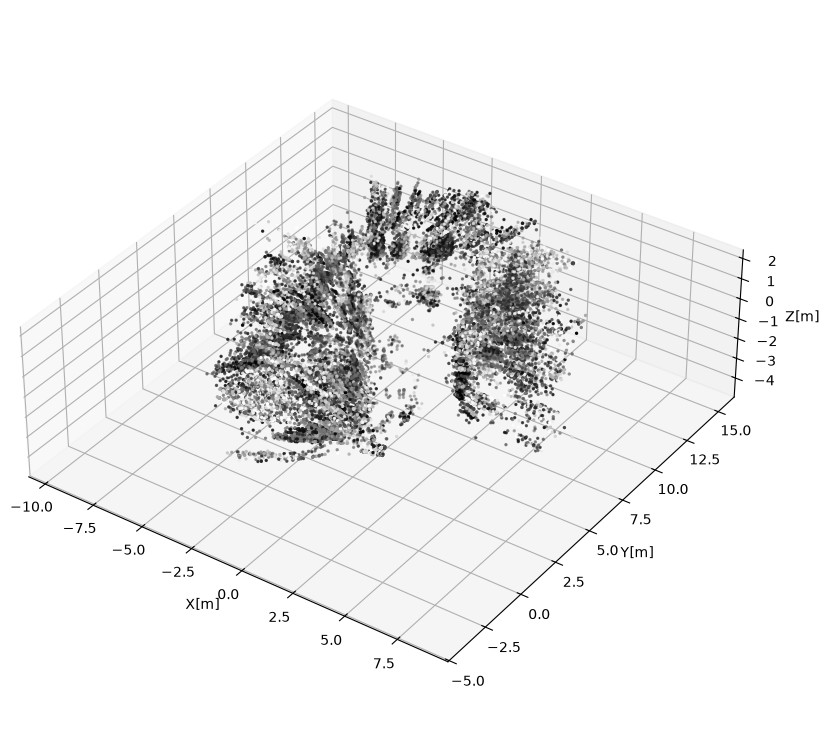

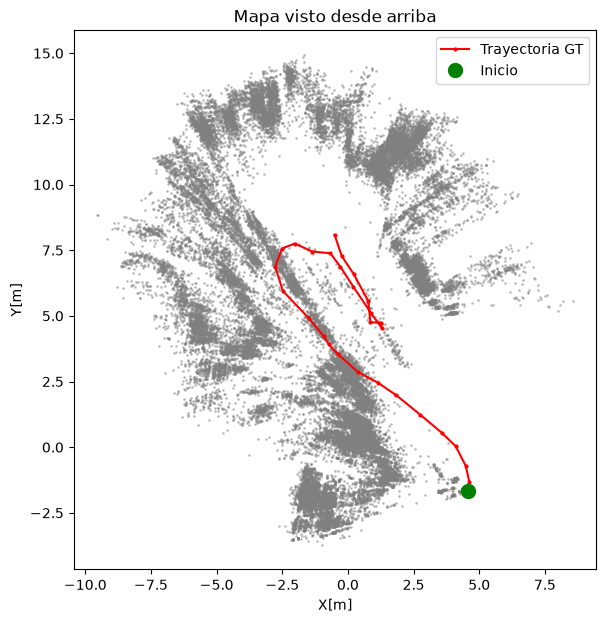

In [10]:
from scipy.spatial.transform import Rotation as Rot

STEP = 30
T_INI, T_FIN = 30, 90
Z_MAX = 6
MAX_DIST_F = 50

# Todos los timestamps que toma el ground-truth
gt_ts = np.array([g[0] for g in ground_truth], dtype=np.int64)
t0 = gt_ts[0]


frames = [n for n in list_izq if T_INI <= (int(n[:-4]) - t0) / 1e9 <= T_FIN][::STEP]
#print("Frames totales:", len(frames))


# Rotación de cámara rectificada a body
# R_left : Extrinsecos de las cámaras sobre el IMU
# Rl^T: Inversa de la rectificada (coincide con traspuesta), la devuelve a su estado original 
R_bc = R_left @ Rl.T

map_points = []

fig = plt.figure(figsize=(8, 8))
axs = fig.add_subplot(projection="3d")
processed_frames = 0

for frame in frames:
    ts = int(frame[:-4])
    # No coinciden los timestamps de las imagenes con lo que se guarda en el GT, así que se agarran
    # números epoch cercanos
    j = np.abs(gt_ts - ts).argmin()
    if abs(gt_ts[j] - ts) > 5_000_000:
        continue

    #print(f'j: {j}')
    #print(f'gt_ts: \t{gt_ts[j]}')
    #print(f'ts: \t{ts}')
    #print('============')
    
    # Hacemos algo similar a los anteriores ejercicios
    # Rectificamos
    left_raw = cv2.imread(str(SEQ_DIR/"cam0"/frame), cv2.IMREAD_GRAYSCALE)
    right_raw = cv2.imread(str(SEQ_DIR/"cam1"/frame), cv2.IMREAD_GRAYSCALE)

    left_rect = rectify(left_raw, Kl, Dl, Rl, Pl, size)
    right_rect = rectify(right_raw, Kr, Dr, Rr, Pr, size)

    # Obtenemos keypoints
    left_kp, left_desc = orb.detectAndCompute(left_rect, None)
    right_kp, right_desc = orb.detectAndCompute(right_rect, None)


    cand = [m for m in matcher.match(left_desc, right_desc) 
           if m.distance < MAX_DIST_F] # Matching con distancia a menos de la máxima configurada

    pts_l = np.float32([left_kp[m.queryIdx].pt for m in cand])
    pts_r = np.float32([right_kp[m.trainIdx].pt for m in cand])


    # Aplicamos RANSAC y nos quedamos con inliers
    _, mask = cv2.findFundamentalMat(pts_l, pts_r, cv2.FM_RANSAC, 1.0, 0.999)
    if mask is None:
        continue

    inl = mask.ravel().astype(bool)
    pts_l = pts_l[inl]
    pts_r = pts_r[inl]

    # Triangulamos y filtramos
    P_cam = triangular(pts_l, pts_r)
    ok = (P_cam[:, 2] > 0) & (P_cam[:, 2] < Z_MAX)  # (*)
    #break
    
    P_cam = P_cam[ok]
    pts_l = pts_l[ok]

    #print(f"Puntos presentes: {pts_l}")
    #print(f'j: {j}')
    #print(ground_truth[j])
    # camara -> body -> W (pose del ground-truth)
    qw, qx, qy, qz = ground_truth[j][4:8]
    
    R_wb = Rot.from_quat([qx, qy, qz, qw])  # Rotación IMU
    t_wb = np.array(ground_truth[j][1:4]) # Traslación
    
    P_body = P_cam @ R_bc.T + T_left
    P_w = R_wb.apply(P_body) + t_wb

    x = np.round(pts_l[:, 0]).astype(int)
    y = np.round(pts_l[:, 1]).astype(int)
    colors = np.repeat(left_rect[y, x][:, None] / 255.0, 3, axis=1)

    axs.scatter(P_w[:, 0], P_w[:, 1], P_w[:, 2], c=colors, s=2)
    map_points.append(P_w)
    processed_frames += 1

map_points = np.vstack(map_points)

axs.set(xlabel="X[m]", ylabel="Y[m]", zlabel="Z[m]")
axs.set_box_aspect(np.ptp(map_points, axis=0))
axs.view_init(elev=35, azim=-55)

fig.tight_layout()
fig.savefig(FIG_DIR / "2f_feature_mapping.png", dpi=150)
plt.show()

selected = [np.abs(gt_ts - int(n[:-4])).argmin() for n in frames]
trayectory = np.array([ground_truth[k][1:4] for k in selected])

fig2, ax = plt.subplots(figsize=(7, 7))
ax.scatter(map_points[:, 0], map_points[:, 1], s=1, c="gray", alpha=0.4)
ax.plot(trayectory[:, 0], trayectory[:, 1], "r.-", ms=4, label="Trayectoria GT")
ax.plot(*trayectory[0, :2], "go", ms=10, label="Inicio")
ax.set_aspect("equal"); ax.set_xlabel("X[m]"); ax.set_ylabel("Y[m]")
ax.legend(); ax.set_title("Mapa visto desde arriba")
fig2.savefig(FIG_DIR / "2f_top_view.png", dpi=150)
plt.show()


## Ej.2g. Mapa de disparidad

_Fuertemente basado en https://reintech.io/blog/depth-map-generation-stereo-images-opencv_

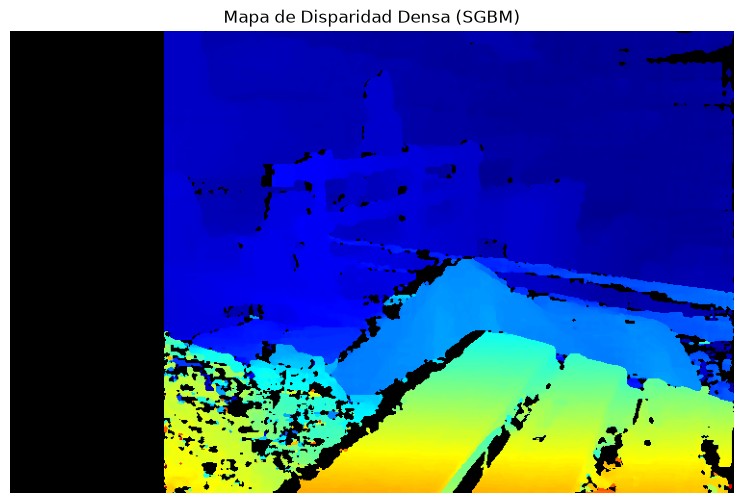

In [11]:
window_size = 5
min_disp = 0
num_disp = 16 * 10

stereo = cv2.StereoSGBM_create(
    minDisparity=min_disp,
    numDisparities=num_disp,
    blockSize=window_size,
    P1=8 * 1 * window_size ** 2,
    P2=32 * 1 * window_size ** 2,
    disp12MaxDiff=1,
    uniquenessRatio=10,
    speckleWindowSize=100,
    speckleRange=32,
    preFilterCap=63,
    mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY
)

left_raw = cv2.imread(str(SEQ_DIR/"cam0"/FRAME), cv2.IMREAD_GRAYSCALE)
right_raw = cv2.imread(str(SEQ_DIR/"cam1"/FRAME), cv2.IMREAD_GRAYSCALE)

left_rect = rectify(left_raw, Kl, Dl, Rl, Pl, size)
right_rect = rectify(right_raw, Kr, Dr, Rr, Pr, size)

# El algoritmo calcula la disparidad tomando como referencia la imagen izquierda
disp_16b = stereo.compute(left_rect, right_rect)

# OpenCV devuelve el mapa multiplicado por 16. Dividimos para obtener píxeles reales
disparity = disp_16b.astype(np.float32) / 16.0


# Creamos una máscara para aislar los píxeles válidos (OpenCV marca errores con valores <= 0)
mask_valid = disparity > 0

vis_disp = np.zeros_like(disparity, dtype=np.uint8)

# Normalizamos
if disparity[mask_valid].size > 0:
    d_min = disparity[mask_valid].min()
    d_max = disparity[mask_valid].max()
    vis_disp[mask_valid] = ((disparity[mask_valid] - d_min) / (d_max - d_min) * 255).astype(np.uint8)

vis_color = cv2.applyColorMap(vis_disp, cv2.COLORMAP_JET)

vis_color[~mask_valid] = [0, 0, 0]

show(vis_color, "Mapa de Disparidad Densa (SGBM)", (10, 6))
save(vis_color, "2g_disparity.png")


## Ej.2h. Reconstruir la Escena 3D de manera Densa

Q:
 [[   1.        0.        0.     -371.3301]
 [   0.        1.        0.     -256.033 ]
 [   0.        0.        0.      439.2613]
 [   0.        0.        9.1258   -0.    ]]


C:\Users\erigi\AppData\Local\Temp\ipykernel_19204\1355669163.py:25: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  ax.scatter(a, b, c=sub_color, cmap="gray", vmin=0, vmax=255, s=1)
C:\Users\erigi\AppData\Local\Temp\ipykernel_19204\1355669163.py:35: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  ax3.scatter(sub[:, 0], sub[:, 2], -sub[:, 1], c=sub_color, cmap="gray", vmin=0, vmax=255, s=1)


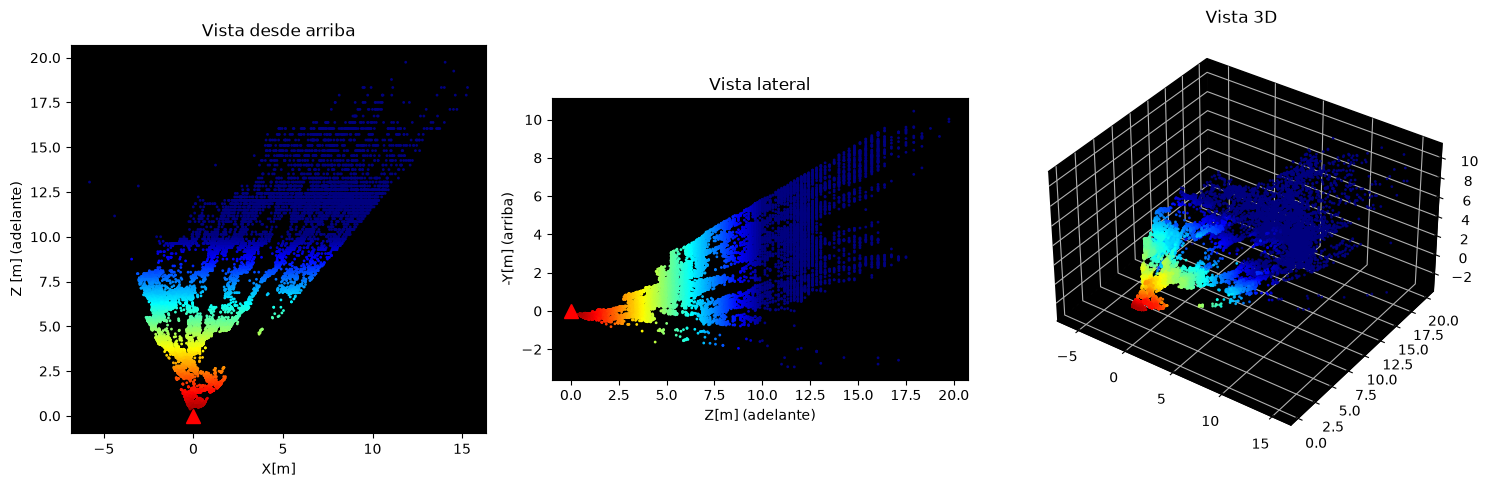

In [12]:
# Generamos la matriz Q reproyección
R1, R2, P1, P2, Q, _, _ = cv2.stereoRectify(
    Kl, Dl, Kr, Dr, size, R_stereo, T_stereo.reshape(3, 1),
    flags=cv2.CALIB_ZERO_DISPARITY, alpha=0
)
print("Q:\n", np.round(Q, 4))

# Convertimos a 3D
xyz = cv2.reprojectImageTo3D(disparity, Q)

# Color de cada punto según el entorno 3D
z_norm = np.clip(xyz[:, :, 2] / 10 * 255, 0, 255).astype(np.uint8)
colors = cv2.applyColorMap(z_norm, cv2.COLORMAP_JET).squeeze() / 255

# Nos quedamos con los píxeles de disparidad válida (mask_valid, del 2g) y a menos de 20m
mask_3d = mask_valid & (xyz[:, :, 2] > 0) & (xyz[:, :, 2] < 20)
pts_dense = xyz[mask_3d]
colors_mask = colors[mask_3d]

# Como Son muchos puntos, tomamos 1 de cada 10. Puede quitarse el filtro, pero tarda
sub = pts_dense[::10]
sub_color = colors_mask[::10]

def draw_view(ax, a, b, xlabel, ylabel, title):
    ax.scatter(a, b, c=sub_color, cmap="gray", vmin=0, vmax=255, s=1)
    ax.plot(0, 0, "r^", ms=10)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.set_aspect("equal"); ax.set_facecolor("black")

fig = plt.figure(figsize=(15, 5))
draw_view(fig.add_subplot(1, 3, 1), sub[:, 0], sub[:, 2], "X[m]", "Z [m] (adelante)", "Vista desde arriba")
draw_view(fig.add_subplot(1, 3, 2), sub[:, 2], -sub[:, 1], "Z[m] (adelante)", "-Y[m] (arriba)", "Vista lateral")

ax3 = fig.add_subplot(1, 3, 3, projection="3d")
ax3.scatter(sub[:, 0], sub[:, 2], -sub[:, 1], c=sub_color, cmap="gray", vmin=0, vmax=255, s=1)
ax3.set_box_aspect(np.ptp(sub[:, [0, 2, 1]], axis=0))
for axis in (ax3.xaxis, ax3.yaxis, ax3.zaxis):
    axis.set_pane_color((0, 0, 0, 1))
ax3.view_init(elev=35, azim=-55)
ax3.set_title("Vista 3D")

fig.tight_layout()
fig.savefig(FIG_DIR / "2h_dense_pointcloud.png", dpi=150)
plt.show()

## Ej.2i. Dense Mapping con Localización ground-truth

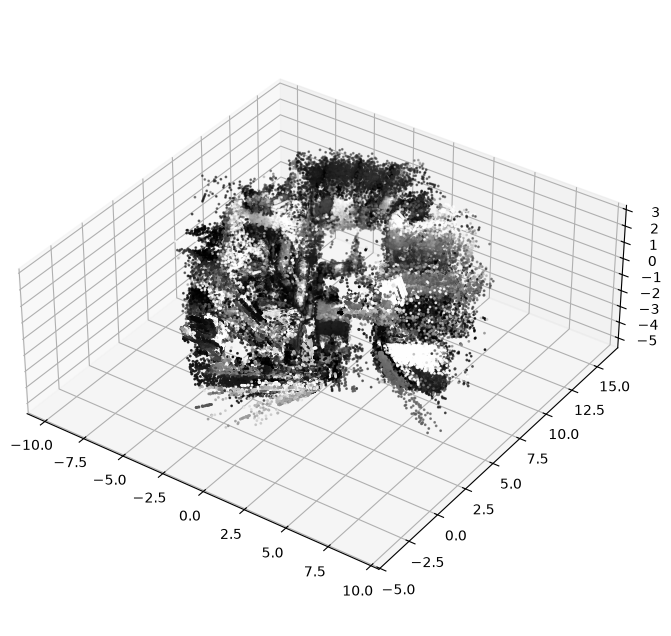

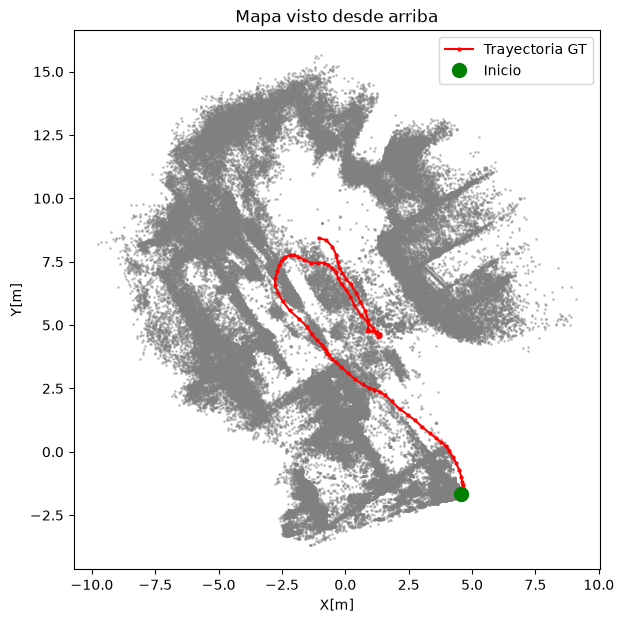

In [13]:
STEP = 10
T_INI, T_FIN = 30, 90
WINDOW = 8
Z_MAX = 6

gt = np.array(ground_truth)
frames = [n for n in list_izq if T_INI <= (int(n[:-4]) - gt_ts[0]) / 1e9 <= T_FIN][::STEP]

map_points, grises = [], []
for frame in frames:
    j = np.abs(gt_ts - int(frame[:-4])).argmin()
    if abs(gt_ts[j] - int(frame[:-4])) > 5_000_000:
        continue

    left_rect = rectify(cv2.imread(str(SEQ_DIR/"cam0"/frame), cv2.IMREAD_GRAYSCALE), Kl, Dl, Rl, Pl, size)
    right_rect = rectify(cv2.imread(str(SEQ_DIR/"cam1"/frame), cv2.IMREAD_GRAYSCALE), Kr, Dr, Rr, Pr, size)

    disp = stereo.compute(left_rect, right_rect).astype(np.float32) / 16.0
    xyz = cv2.reprojectImageTo3D(disp, Q)

    # Submuestreo porque sino no termina más
    disp, xyz, left_rect = disp[::WINDOW, ::WINDOW], xyz[::WINDOW, ::WINDOW], left_rect[::WINDOW, ::WINDOW]
    ok = (disp > 0) & (xyz[:, :, 2] > 0.3) & (xyz[:, :, 2] < Z_MAX)

    # cámara -> body -> mundo
    R_wb = Rot.from_quat(gt[j, [5, 6, 7, 4]])
    map_points.append(R_wb.apply(xyz[ok] @ R_bc.T + T_left) + gt[j, 1:4])
    grises.append(left_rect[ok])

P, G = np.vstack(map_points), np.concatenate(grises)
# print("Pts en el mapa:", len(P))

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection="3d")
ax.scatter(P[:, 0], P[:, 1], P[:, 2], c=G, cmap="gray", vmin=0, vmax=255, s=1)
ax.set_box_aspect(np.ptp(P, axis=0))
ax.view_init(elev=35, azim=-55)
fig.savefig(FIG_DIR / "2i_dense_mapping.png", dpi=150)
plt.show()


selected = [np.abs(gt_ts - int(n[:-4])).argmin() for n in frames]
trayectory = np.array([ground_truth[k][1:4] for k in selected])

fig2, ax = plt.subplots(figsize=(7, 7))
ax.scatter(P[:, 0], P[:, 1], s=1, c="gray", alpha=0.4)
ax.plot(trayectory[:, 0], trayectory[:, 1], "r.-", ms=4, label="Trayectoria GT")
ax.plot(*trayectory[0, :2], "go", ms=10, label="Inicio")
ax.set_aspect("equal"); ax.set_xlabel("X[m]"); ax.set_ylabel("Y[m]")
ax.legend(); ax.set_title("Mapa visto desde arriba")
fig2.savefig(FIG_DIR / "2i_top_view.png", dpi=150)
plt.show()

## Ej.2j. Estimar la Pose utilizando Correspondencias 3D-3D

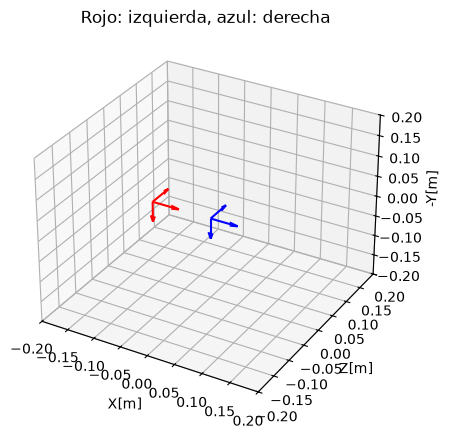

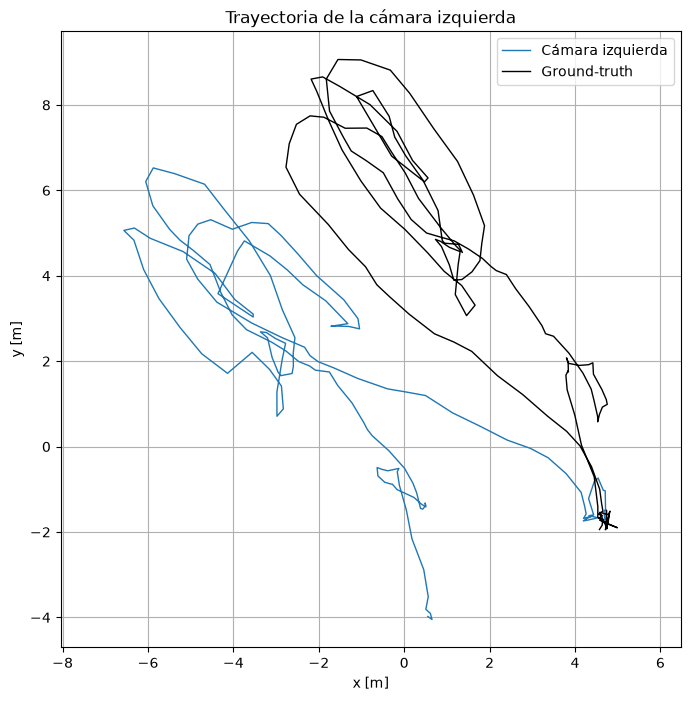

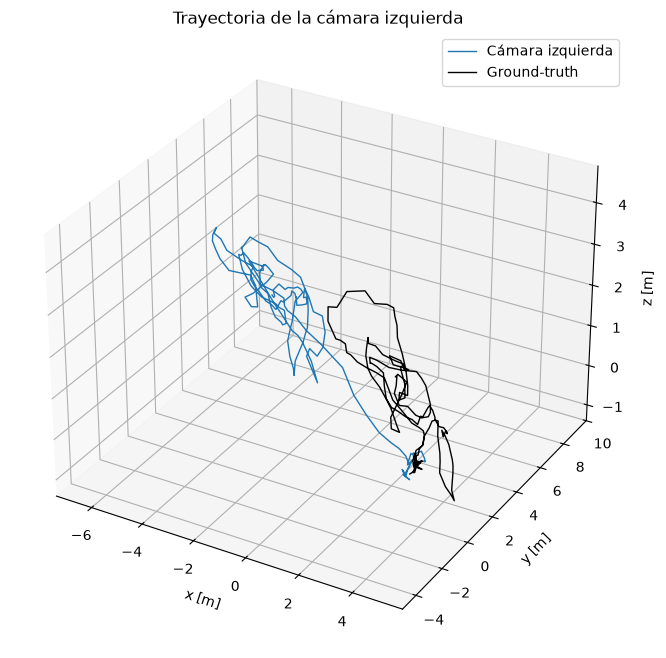

In [14]:
# Matriz esencial
E, _ = cv2.findEssentialMat(new_l, new_r, np.eye(3))

# Descomposición en R y t
_, R, t, _ = cv2.recoverPose(E, new_l, new_r, np.eye(3))
t *= np.linalg.norm(T_stereo)

# Poses de las cámaras
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection="3d")
ax.set_title("Rojo: izquierda, azul: derecha")
ax.set_xlabel("X[m]"); ax.set_ylabel("Z[m]"); ax.set_zlabel("-Y[m]")
ax.set_xlim(-0.2, 0.2); ax.set_ylim(-0.2, 0.2); ax.set_zlim(-0.2, 0.2)
ejeX = np.array([1, 0, 0])
ejeY = np.array([0, 1, 0])
ejeZ = np.array([0, 0, 1])
scale = 0.05
oL = np.array([0, 0, 0])
V = scale * np.array([ejeX, ejeY, ejeZ])
plt.quiver(*oL, V[:, 0], V[:, 2], -V[:, 1], color="blue")
V = scale * np.matmul(np.array([ejeX, ejeY, ejeZ]), R)
plt.quiver(*t, V[:, 0], V[:, 2], -V[:, 1], color="red")
plt.show()
fig.savefig(FIG_DIR / "2j_ejes.png", dpi=150)

t = np.array(ground_truth[0][1:4])
qw, qx, qy, qz = ground_truth[0][4:8]
R = np.matrix([[1-2*(qy**2+qz**2), 2*(qx*qy-qz*qw), 2*(qx*qz+qy*qw)],
               [2*(qx*qy+qz*qw), 1-2*(qx**2+qz**2), 2*(qy*qz-qx*qw)],
               [2*(qx*qz-qy*qw), 2*(qy*qz+qx*qw), 1-2*(qx**2+qy**2)]])
R = R @ R_left @ Rl.T
X = [t[0].item()]
Y = [t[1].item()]
Z = [t[2].item()]
STEP = 20
gt_t = np.array([row[0] for row in ground_truth], dtype=np.int64)
K = Pl[:, :3]
for i in range(1, len(list_izq), STEP):
    img_raw = cv2.imread(SEQ_DIR/"cam0"/list_izq[i], cv2.IMREAD_GRAYSCALE)
    img_rect = rectify(img_raw, Kl, Dl, Rl, Pl, size)
    img_kp, img_desc = orb.detectAndCompute(img_rect, None)
    matches = matcher.match(desc_l, img_desc)
    good = [m for m in matches if m.distance < MAX_DIST]
    pts_l = np.array([kp_l[m.queryIdx].pt for m in good], dtype=np.float64)
    img_pts = np.array([img_kp[m.trainIdx].pt for m in good], dtype=np.float64)
    E, _ = cv2.findEssentialMat(pts_l, img_pts, K)
    _, R1, t1, _ = cv2.recoverPose(E, pts_l, img_pts, K)
    j1 = np.abs(gt_t - int(list_izq[i][:-4])).argmin()
    j0 = np.abs(gt_t - int(list_izq[max(i - STEP, 0)][:-4])).argmin()
    dt = np.array(ground_truth[j1][1:4]) - np.array(ground_truth[j0][1:4])
    t1 *= np.linalg.norm(dt)
    ch = np.matmul(R, -R1.T @ t1)
    dt = np.array([ch[0].item(), ch[1].item(), ch[2].item()])
    t = np.add(t, dt)
    R = np.matmul(R, R1.T) 
    X.append(t[0].item())
    Y.append(t[1].item())
    Z.append(t[2].item())
    kp_l = img_kp
    desc_l = img_desc
    pts_l = img_pts


# Ground-truth real en los mismos instantes que los frames procesados

gt_idx = [0] + [np.abs(gt_t - int(list_izq[i][:-4])).argmin() for i in range(1, len(list_izq), STEP)]
GT = np.array(ground_truth)[gt_idx, 1:4]

plt.figure(figsize=(8, 8))
plt.plot(X, Y, label='Cámara izquierda', linewidth=1)
plt.plot(GT[:, 0], GT[:, 1], 'k-', label='Ground-truth', linewidth=1)
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.title('Trayectoria de la cámara izquierda')
plt.legend()
plt.axis('equal')
plt.grid(True)
plt.savefig(FIG_DIR / '2j_trayectoria2d.png', dpi=150, bbox_inches='tight')
plt.show()
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(X, Y, Z, label='Cámara izquierda', linewidth=1)
ax.plot(GT[:, 0], GT[:, 1], GT[:, 2], 'k-', label='Ground-truth', linewidth=1)
ax.set_xlabel('x [m]')
ax.set_ylabel('y [m]')
ax.set_zlabel('z [m]')
ax.set_title('Trayectoria de la cámara izquierda')
ax.legend()
plt.savefig(FIG_DIR / '2j_trayectoria3d.png', dpi=150, bbox_inches='tight')
plt.show()

## Ej.2k. Estimar la Pose utilizando Correspondencias 3D-2D

Para este ejercicio, usamos `solvePnPRansac` para resolver el problema `PnP`. Esta función nos devuelve un vector de rotación (https://docs.opencv.org/4.13.0/d9/d0c/group__calib3d.html#ga50620f0e26e02caa2e9adc07b5fbf24e) que después convertimos a matriz con el método `Rodrigues` (https://docs.opencv.org/4.13.0/d9/d0c/group__calib3d.html#ga61585db663d9da06b68e70cfbf6a1eac)

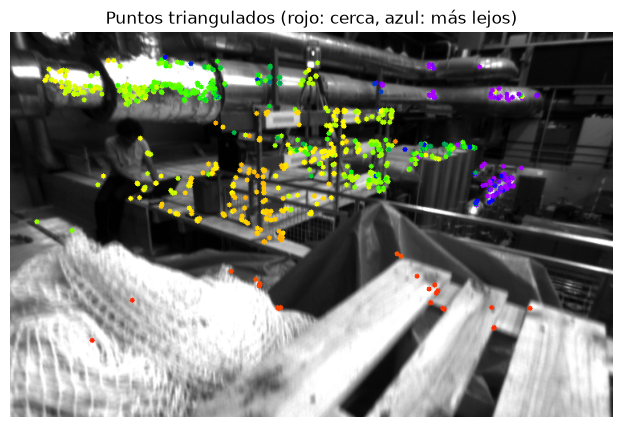

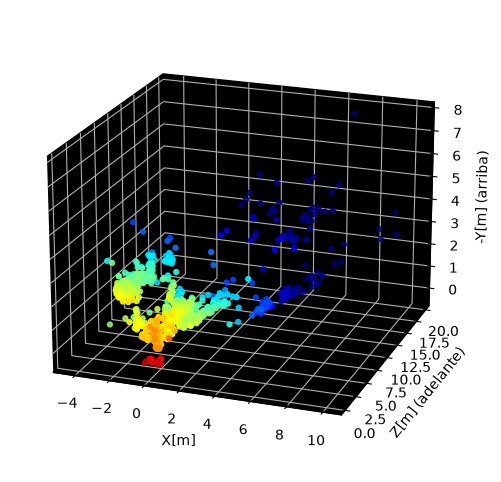

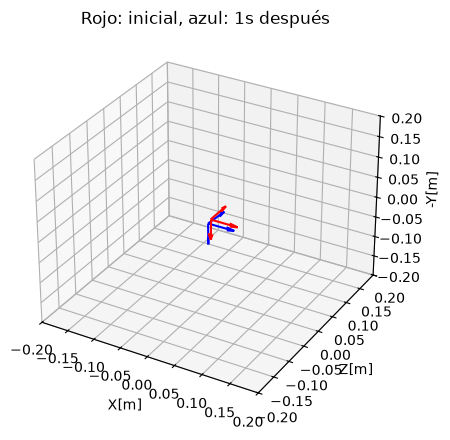

In [15]:
# Recalculamos lo que se necesita porque algunas celdas pisan algunos valores importantes
K = Pl[:, :3]
left_rect = rectify(cv2.imread(str(LEFT_PATH), cv2.IMREAD_GRAYSCALE), Kl, Dl, Rl, Pl, size)
right_rect = rectify(cv2.imread(str(RIGHT_PATH), cv2.IMREAD_GRAYSCALE), Kr, Dr, Rr, Pr, size)
kp_l, desc_l = orb.detectAndCompute(left_rect, None)
kp_r, desc_r = orb.detectAndCompute(right_rect, None)
cand = [m for m in matcher.match(desc_l, desc_r) if m.distance < MAX_DIST_E]
pts_l = np.float32([kp_l[m.queryIdx].pt for m in cand])
pts_r = np.float32([kp_r[m.trainIdx].pt for m in cand])
_, mask = cv2.findFundamentalMat(pts_l, pts_r, cv2.FM_RANSAC, 1.0, 0.999)
inl = mask.ravel().astype(bool)
new_l, new_r = pts_l[inl], pts_r[inl]
P_after = triangular(new_l, new_r)
# ---
# ---
# ---


# Imagen izquierda de un segundo después
sndimg1 = cv2.imread(LEFT_PATH2, cv2.IMREAD_GRAYSCALE)

# Imagen rectificada
snd_left_rect = rectify(sndimg1, Kl, Dl, Rl, Pl, size)

# Matcheamos keypoints entre las imágenes izquierdas
snd_kp_l, snd_desc_l = orb.detectAndCompute(snd_left_rect, None)
ds_l = np.array([desc_l[m.queryIdx] for m in cand])[inl]
matches = matcher.match(ds_l, snd_desc_l)
snd_good = [m for m in matches if m.distance < MAX_DIST]

# Filtramos los puntos matcheados
pts_l = np.array([new_l[m.queryIdx] for m in snd_good], dtype=np.float64)
snd_pts_l = np.array([snd_kp_l[m.trainIdx].pt for m in snd_good], dtype=np.float64)
new_P = np.array([P_after[m.queryIdx] for m in snd_good], dtype=np.float64)

# Nos quedamos con los puntos delante de la cámara y a menos de 20 m
ok = (new_P[:, 2] > 0.3) & (new_P[:, 2] < 20)
new_P, snd_pts_l = new_P[ok], snd_pts_l[ok]

# Resolvemos PnP
_, rvec, tvec, inliers = cv2.solvePnPRansac(new_P, snd_pts_l, K, np.zeros(5)) # Nos devuelve un vector de rotación. 
R2, jacobian = cv2.Rodrigues(rvec) # Pasamos a matriz de rotación. 
snd_P = new_P @ R2.T + tvec.ravel()

# Visualizamos los puntos triangulados
vis_3d = cv2.cvtColor(snd_left_rect, cv2.COLOR_GRAY2BGR)
z_norm = np.clip(snd_P[:, 2] / 10 * 255, 0, 255).astype(np.uint8)
colors_z = cv2.applyColorMap(z_norm, cv2.COLORMAP_RAINBOW).squeeze()

for (u, v), color in zip(snd_pts_l, colors_z):
    cv2.circle(vis_3d, (int(u), int(v)), 3, color.tolist(), -1)
show(vis_3d, "Puntos triangulados (rojo: cerca, azul: más lejos)")
save(vis_3d, "2k_depth.png")

# Nube de puntos un segundo después
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
colors_z = cv2.applyColorMap(z_norm, cv2.COLORMAP_JET).squeeze() / 255
ax.scatter(snd_P[:, 0], snd_P[:, 2], -snd_P[:, 1], c=colors_z, s=12)

for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_pane_color((0, 0, 0, 1))
ax.set_xlabel("X[m]"); ax.set_ylabel("Z[m] (adelante)"); ax.set_zlabel("-Y[m] (arriba)")
ax.view_init(elev=20, azim=-70)
fig.savefig(FIG_DIR / "2k_pointcloud.png", dpi=150)
plt.show()

# Poses de la cámara izquierda
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(projection="3d")
ax.set_title("Rojo: inicial, azul: 1s después")
ax.set_xlabel("X[m]"); ax.set_ylabel("Z[m]"); ax.set_zlabel("-Y[m]")
ax.set_xlim(-0.2, 0.2); ax.set_ylim(-0.2, 0.2); ax.set_zlim(-0.2, 0.2)
xax = np.array([1, 0, 0])
yax = np.array([0, 1, 0])
zax = np.array([0, 0, 1])
scale = 0.05
oL = np.array([0, 0, 0])
V = scale * np.array([xax, yax, zax])
plt.quiver(*oL, V[:, 0], V[:, 2], -V[:, 1], color="red")
c2 = -R2.T @ tvec.ravel()
sndL = np.array([c2[0], c2[2], -c2[1]])
V = scale * np.matmul(np.array([xax, yax, zax]), R2)
plt.quiver(*sndL, V[:, 0], V[:, 2], -V[:, 1], color="blue")
plt.show()
fig.savefig(FIG_DIR / "2k_ejes.png", dpi=150)